In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

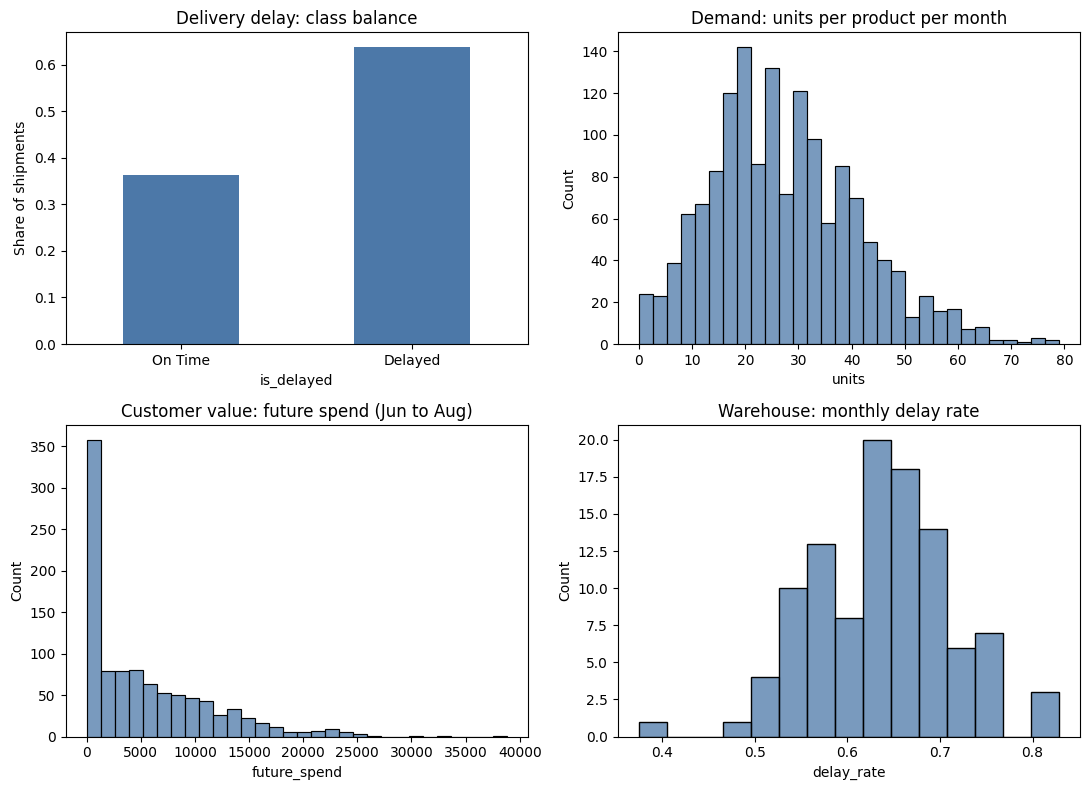

delay class counts: {1: 3186, 0: 1814}
skew  demand units: 0.53 | future spend: 1.36 | warehouse delay rate: -0.12


In [3]:

P = Path("../Data/Processed_Datasets")
FIG = Path("../Reports/figures")
FIG.mkdir(parents=True, exist_ok=True)

delay = pd.read_csv(P / "delay_features.csv", parse_dates=["OrderDate"])
demand = pd.read_csv(P / "demand_features.csv")
cust = pd.read_csv(P / "customer_features.csv")
wh = pd.read_csv(P / "warehouse_features.csv")

fig, ax = plt.subplots(2, 2, figsize=(11, 8))
c = "#4C78A8"

(delay["is_delayed"].value_counts(normalize=True).sort_index()
      .rename({0: "On Time", 1: "Delayed"}).plot.bar(ax=ax[0, 0], color=c, rot=0))
ax[0, 0].set_title("Delivery delay: class balance")
ax[0, 0].set_ylabel("Share of shipments")

sns.histplot(demand["units"], bins=30, ax=ax[0, 1], color=c)
ax[0, 1].set_title("Demand: units per product per month")

sns.histplot(cust["future_spend"], bins=30, ax=ax[1, 0], color=c)
ax[1, 0].set_title("Customer value: future spend (Jun to Aug)")

sns.histplot(wh["delay_rate"], bins=15, ax=ax[1, 1], color=c)
ax[1, 1].set_title("Warehouse: monthly delay rate")

plt.tight_layout()
plt.savefig(FIG / "target_distributions.png", dpi=150)
plt.show()

print("delay class counts:", delay["is_delayed"].value_counts().to_dict())
print("skew  demand units:", round(demand["units"].skew(), 2),
      "| future spend:", round(cust["future_spend"].skew(), 2),
      "| warehouse delay rate:", round(wh["delay_rate"].skew(), 2))

In [4]:
sets = {"delay": delay, "demand": demand, "customer": cust, "warehouse": wh}
for n, d in sets.items():
    print(f"{n:10s} rows={len(d):5d}  missing cells={int(d.isna().sum().sum())}")

def iqr_outliers(d, cols):
    rows = []
    for c in cols:
        q1, q3 = d[c].quantile([.25, .75])
        iqr = q3 - q1
        n = ((d[c] < q1 - 1.5*iqr) | (d[c] > q3 + 1.5*iqr)).sum()
        rows.append((c, int(n), round(100*n/len(d), 1)))
    return pd.DataFrame(rows, columns=["feature", "n_outliers", "pct"])

print("\nDELAY\n", iqr_outliers(delay, ["order_value","total_qty","n_lines","wh_load_7d"]))
print("\nDEMAND\n", iqr_outliers(demand, ["units","lag_1","total_stock","UnitPrice"]))
print("\nCUSTOMER\n", iqr_outliers(cust, ["future_spend","total_spend","n_orders","avg_order_value"]))
print("\nWAREHOUSE\n", iqr_outliers(wh, ["delay_rate","lag_delay_rate","n_shipments"]))

delay      rows= 5000  missing cells=0
demand     rows= 1500  missing cells=0
customer   rows= 1000  missing cells=0
warehouse  rows=  105  missing cells=0

DELAY
        feature  n_outliers  pct
0  order_value         107  2.1
1    total_qty          79  1.6
2      n_lines          54  1.1
3   wh_load_7d          73  1.5

DEMAND
        feature  n_outliers  pct
0        units          18  1.2
1        lag_1          17  1.1
2  total_stock           6  0.4
3    UnitPrice           0  0.0

CUSTOMER
            feature  n_outliers  pct
0     future_spend          22  2.2
1      total_spend          15  1.5
2         n_orders           2  0.2
3  avg_order_value          19  1.9

WAREHOUSE
           feature  n_outliers  pct
0      delay_rate           1  1.0
1  lag_delay_rate           1  1.0
2     n_shipments           0  0.0


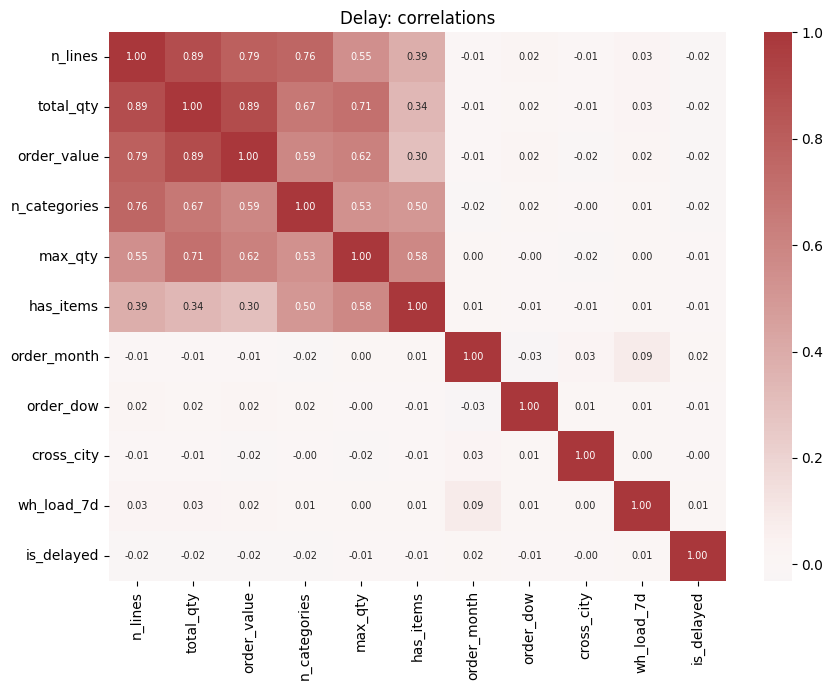

Top correlations with is_delayed:
order_value    -0.025
n_categories   -0.020
n_lines        -0.019
total_qty      -0.019
order_month     0.016
Name: is_delayed, dtype: float64 



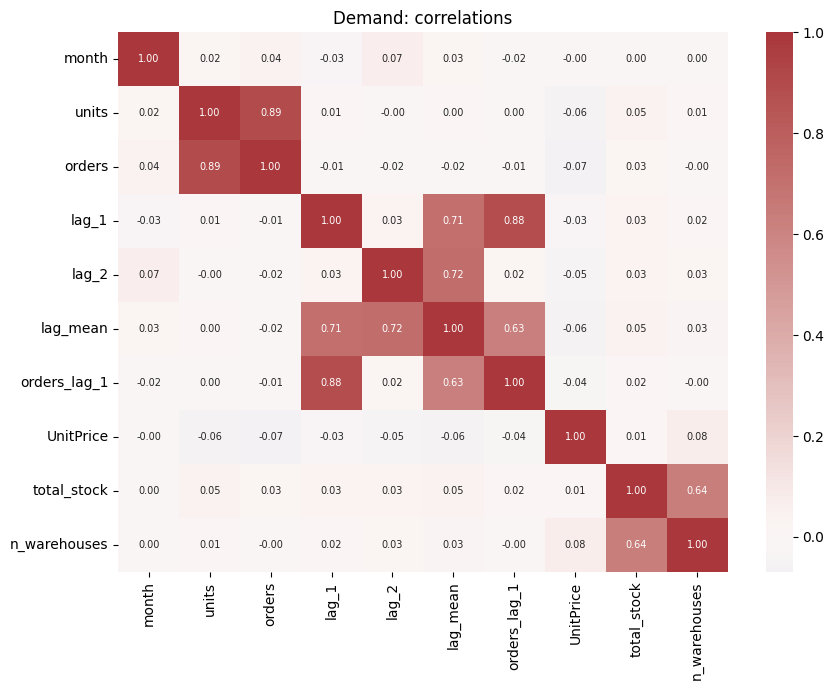

Top correlations with units:
orders         0.888
UnitPrice     -0.055
total_stock    0.046
month          0.022
lag_1          0.008
Name: units, dtype: float64 



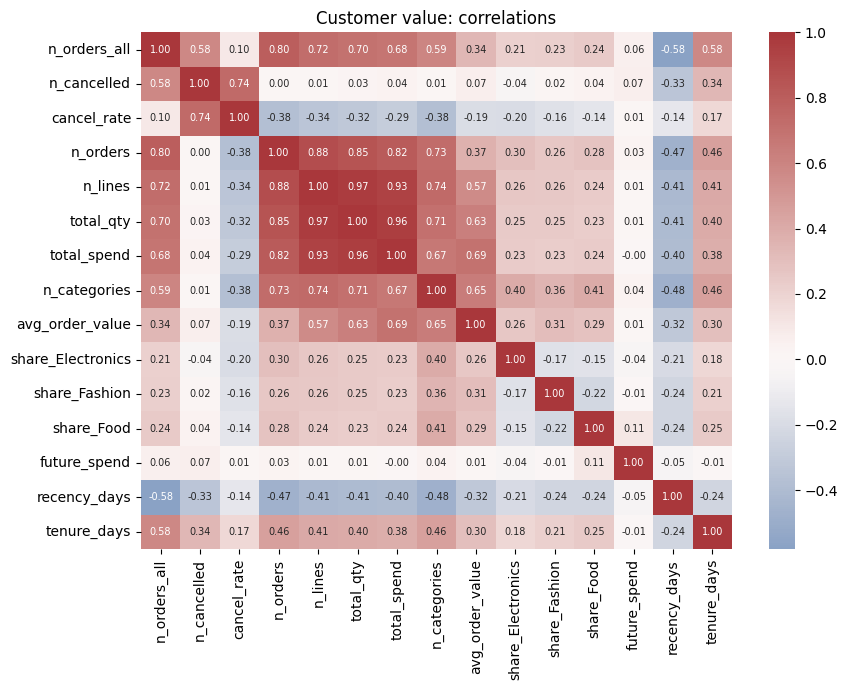

Top correlations with future_spend:
share_Food      0.110
n_cancelled     0.069
n_orders_all    0.058
recency_days   -0.051
n_categories    0.044
Name: future_spend, dtype: float64 



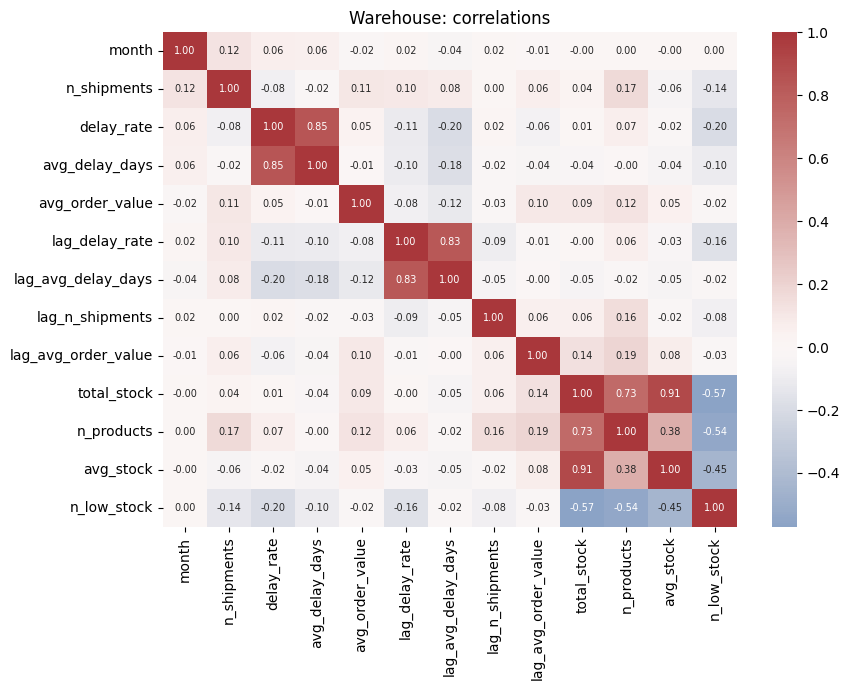

Top correlations with delay_rate:
avg_delay_days        0.846
lag_avg_delay_days   -0.198
n_low_stock          -0.196
lag_delay_rate       -0.106
n_shipments          -0.081
Name: delay_rate, dtype: float64 



In [5]:
def corr_plot(d, target, title, fname, drop=()):
    num = d.select_dtypes("number").drop(columns=list(drop), errors="ignore")
    cm = num.corr()
    plt.figure(figsize=(9, 7))
    sns.heatmap(cm, cmap="vlag", center=0, annot=True, fmt=".2f", annot_kws={"size": 7})
    plt.title(title)
    plt.tight_layout()
    plt.savefig(FIG / fname, dpi=150)
    plt.show()
    print(f"Top correlations with {target}:")
    print(cm[target].drop(target).sort_values(key=abs, ascending=False).head(5).round(3), "\n")

corr_plot(delay, "is_delayed", "Delay: correlations", "corr_delay.png", drop=["DelayDays"])
corr_plot(demand, "units", "Demand: correlations", "corr_demand.png")
corr_plot(cust, "future_spend", "Customer value: correlations", "corr_customer.png")
corr_plot(wh, "delay_rate", "Warehouse: correlations", "corr_warehouse.png")

delay {'order_value': 0.192, 'total_qty': 0.134, 'wh_load_7d': 0.108}
demand {'UnitPrice': 0.21, 'total_stock': 0.181, 'lag_mean': 0.164}
customer {'share_Food': 0.13, 'avg_order_value': 0.129, 'recency_days': 0.11}
warehouse {'lag_avg_delay_days': 0.276, 'avg_stock': 0.191, 'n_low_stock': 0.164}


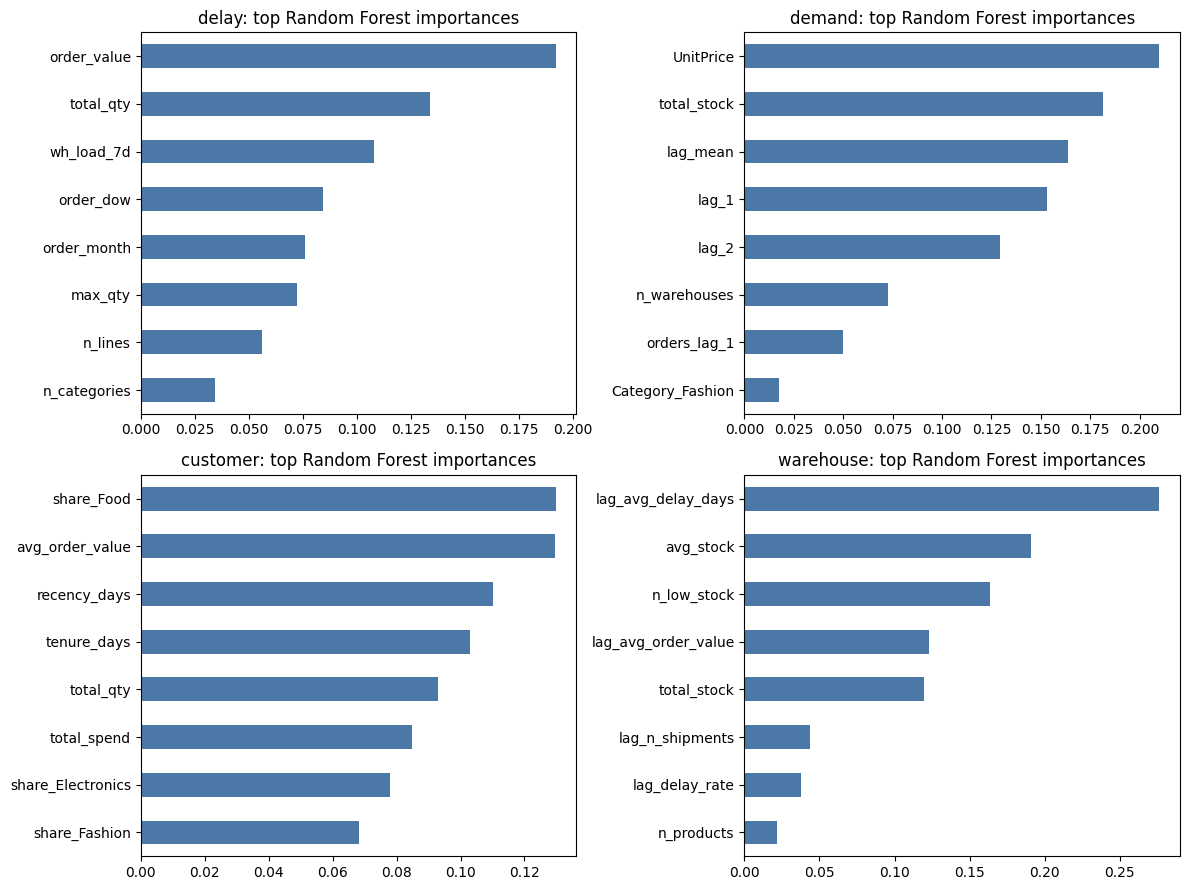

In [6]:
from swiftlog_config import FEATURES
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor

data = {"delay": delay, "demand": demand, "customer": cust, "warehouse": wh}
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for ax, (name, cfg) in zip(axes.ravel(), FEATURES.items()):
    d = data[name]
    tr = d[d["split"] == "train"]
    X = pd.get_dummies(tr[cfg["num"] + cfg["cat"]], columns=cfg["cat"])
    y = tr[cfg["target"]]
    Model = RandomForestClassifier if cfg["task"] == "classification" else RandomForestRegressor
    m = Model(n_estimators=200, min_samples_leaf=10, random_state=42, n_jobs=-1).fit(X, y)
    imp = pd.Series(m.feature_importances_, index=X.columns).sort_values()
    imp.tail(8).plot.barh(ax=ax, color="#4C78A8")
    ax.set_title(f"{name}: top Random Forest importances")
    print(name, imp.sort_values(ascending=False).head(3).round(3).to_dict())

plt.tight_layout()
plt.savefig(FIG / "eda_feature_importance.png", dpi=150)
plt.show()